# Geography and scenarios

Status update for the consultation, 6 Nov 2026. This notebook uses the out-of-fold predictions: each person is scored by a model that never saw their household, then averaged by province. It reads saved results, so nothing is refit.

Questions:
1. Can we trust provincial predicted rates?
2. Is illiteracy spatially clustered?
3. Where are the hotspots, and are they solid?
4. What would more digital uptake change?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image

In [2]:
spatial = Path('../..') / '04_spatial_lisa_simulation'

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Can we trust provincial predicted rates?

We sort people into ten groups by predicted risk and compare the average prediction with the observed rate in each group. Points on the diagonal mean the model is calibrated.

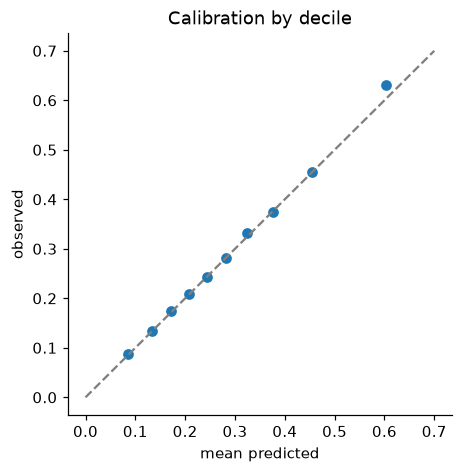

In [3]:
cal = pd.read_csv(spatial / 'oof_calibration_deciles.csv')

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 0.7], [0, 0.7], color='grey', ls='--')
ax.scatter(cal.mean_pred_w, cal.observed_w, color='tab:blue')
ax.set_xlabel('mean predicted')
ax.set_ylabel('observed')
ax.set_title('Calibration by decile')
plt.show()

In [4]:
met = pd.read_csv(spatial / 'oof_model_metrics.csv').round(3)
met[['roc_auc_weighted_oof', 'observed_prevalence_w', 'mean_pred_final_w']]

,roc_auc_weighted_oof,observed_prevalence_w,mean_pred_final_w
0,0.709,0.292,0.288


Mean prediction is 0.288 against 0.292 observed. The top decile is a little low (0.603 vs 0.630). Province averages can be read as risk levels, with that caveat.

Now province by province:

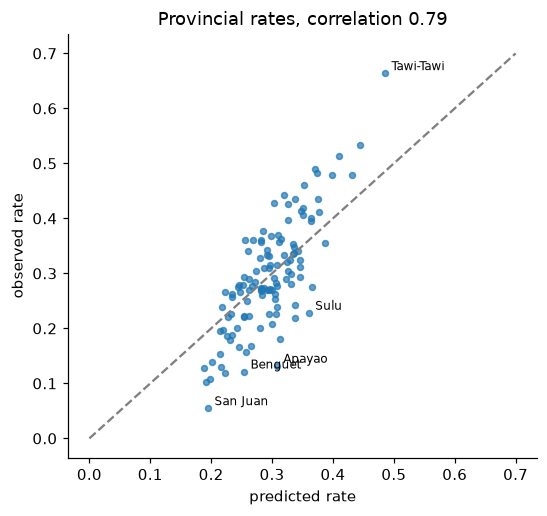

In [5]:
prov = pd.read_csv(spatial / 'province_rates_observed_predicted.csv', encoding='latin-1')
prov = prov.dropna(subset=['obs_rate', 'pred_rate'])
r = prov.obs_rate.corr(prov.pred_rate)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 0.7], [0, 0.7], color='grey', ls='--')
ax.scatter(prov.pred_rate, prov.obs_rate, s=15, alpha=0.7)
far = prov.loc[prov.residual.abs().nlargest(5).index]
for _, row in far.iterrows():
    ax.annotate(row.NAME, (row.pred_rate, row.obs_rate), fontsize=8, xytext=(4, 2), textcoords='offset points')
ax.set_xlabel('predicted rate')
ax.set_ylabel('observed rate')
ax.set_title(f'Provincial rates, correlation {r:.2f}')
plt.show()

Predicted and observed rates track each other closely, so most of the provincial pattern comes from who lives there. The labelled areas are the biggest gaps. Tawi-Tawi is 18 points above what its population profile predicts, Apayao 18 points below.

## 2. Is illiteracy spatially clustered?

Global Moran's I measures whether neighbouring provinces have similar rates. 0 is no pattern, higher is more clustering. We test with 9,999 permutations and two definitions of neighbour.

In [6]:
mor = pd.read_csv(spatial / 'global_morans_i.csv')
mor = mor.pivot(index='variable', columns='weights', values=['I', 'p_sim']).round(4)
mor.loc[['obs_rate', 'pred_rate', 'residual']]

I           p_sim        
weights      knn6   queen    knn6   queen
variable                                 
obs_rate   0.3748  0.3401  0.0001  0.0001
pred_rate  0.6112  0.6492  0.0001  0.0001
residual   0.1110  0.0979  0.0114  0.0933

- Observed rates are clustered (I about 0.34 to 0.38).
- Predicted rates cluster almost twice as strongly. The pattern is mostly compositional.
- What the model does not explain (residual) clusters only weakly, and is not significant under queen contiguity.

## 3. Where are the hotspots, and are they solid?

LISA flags provinces that are high (or low) and surrounded by similar provinces. Our rule is permutation p < 0.05. Because we test 117 provinces at once, we also report the Benjamini-Hochberg false discovery rate (BH-FDR) version, which is stricter.

In [7]:
lisa = pd.read_csv(spatial / 'lisa_clusters.csv', encoding='latin-1')
obs = lisa[lisa.variable == 'obs_rate']

counts = pd.DataFrame({
    'p < 0.05': obs.cluster_p05.value_counts(),
    'BH-FDR': obs.cluster_fdr.value_counts(),
}).fillna(0).astype(int)
counts

,p < 0.05,BH-FDR
High-High,11,0
Low-High,4,1
Low-Low,17,8
Not significant,85,108


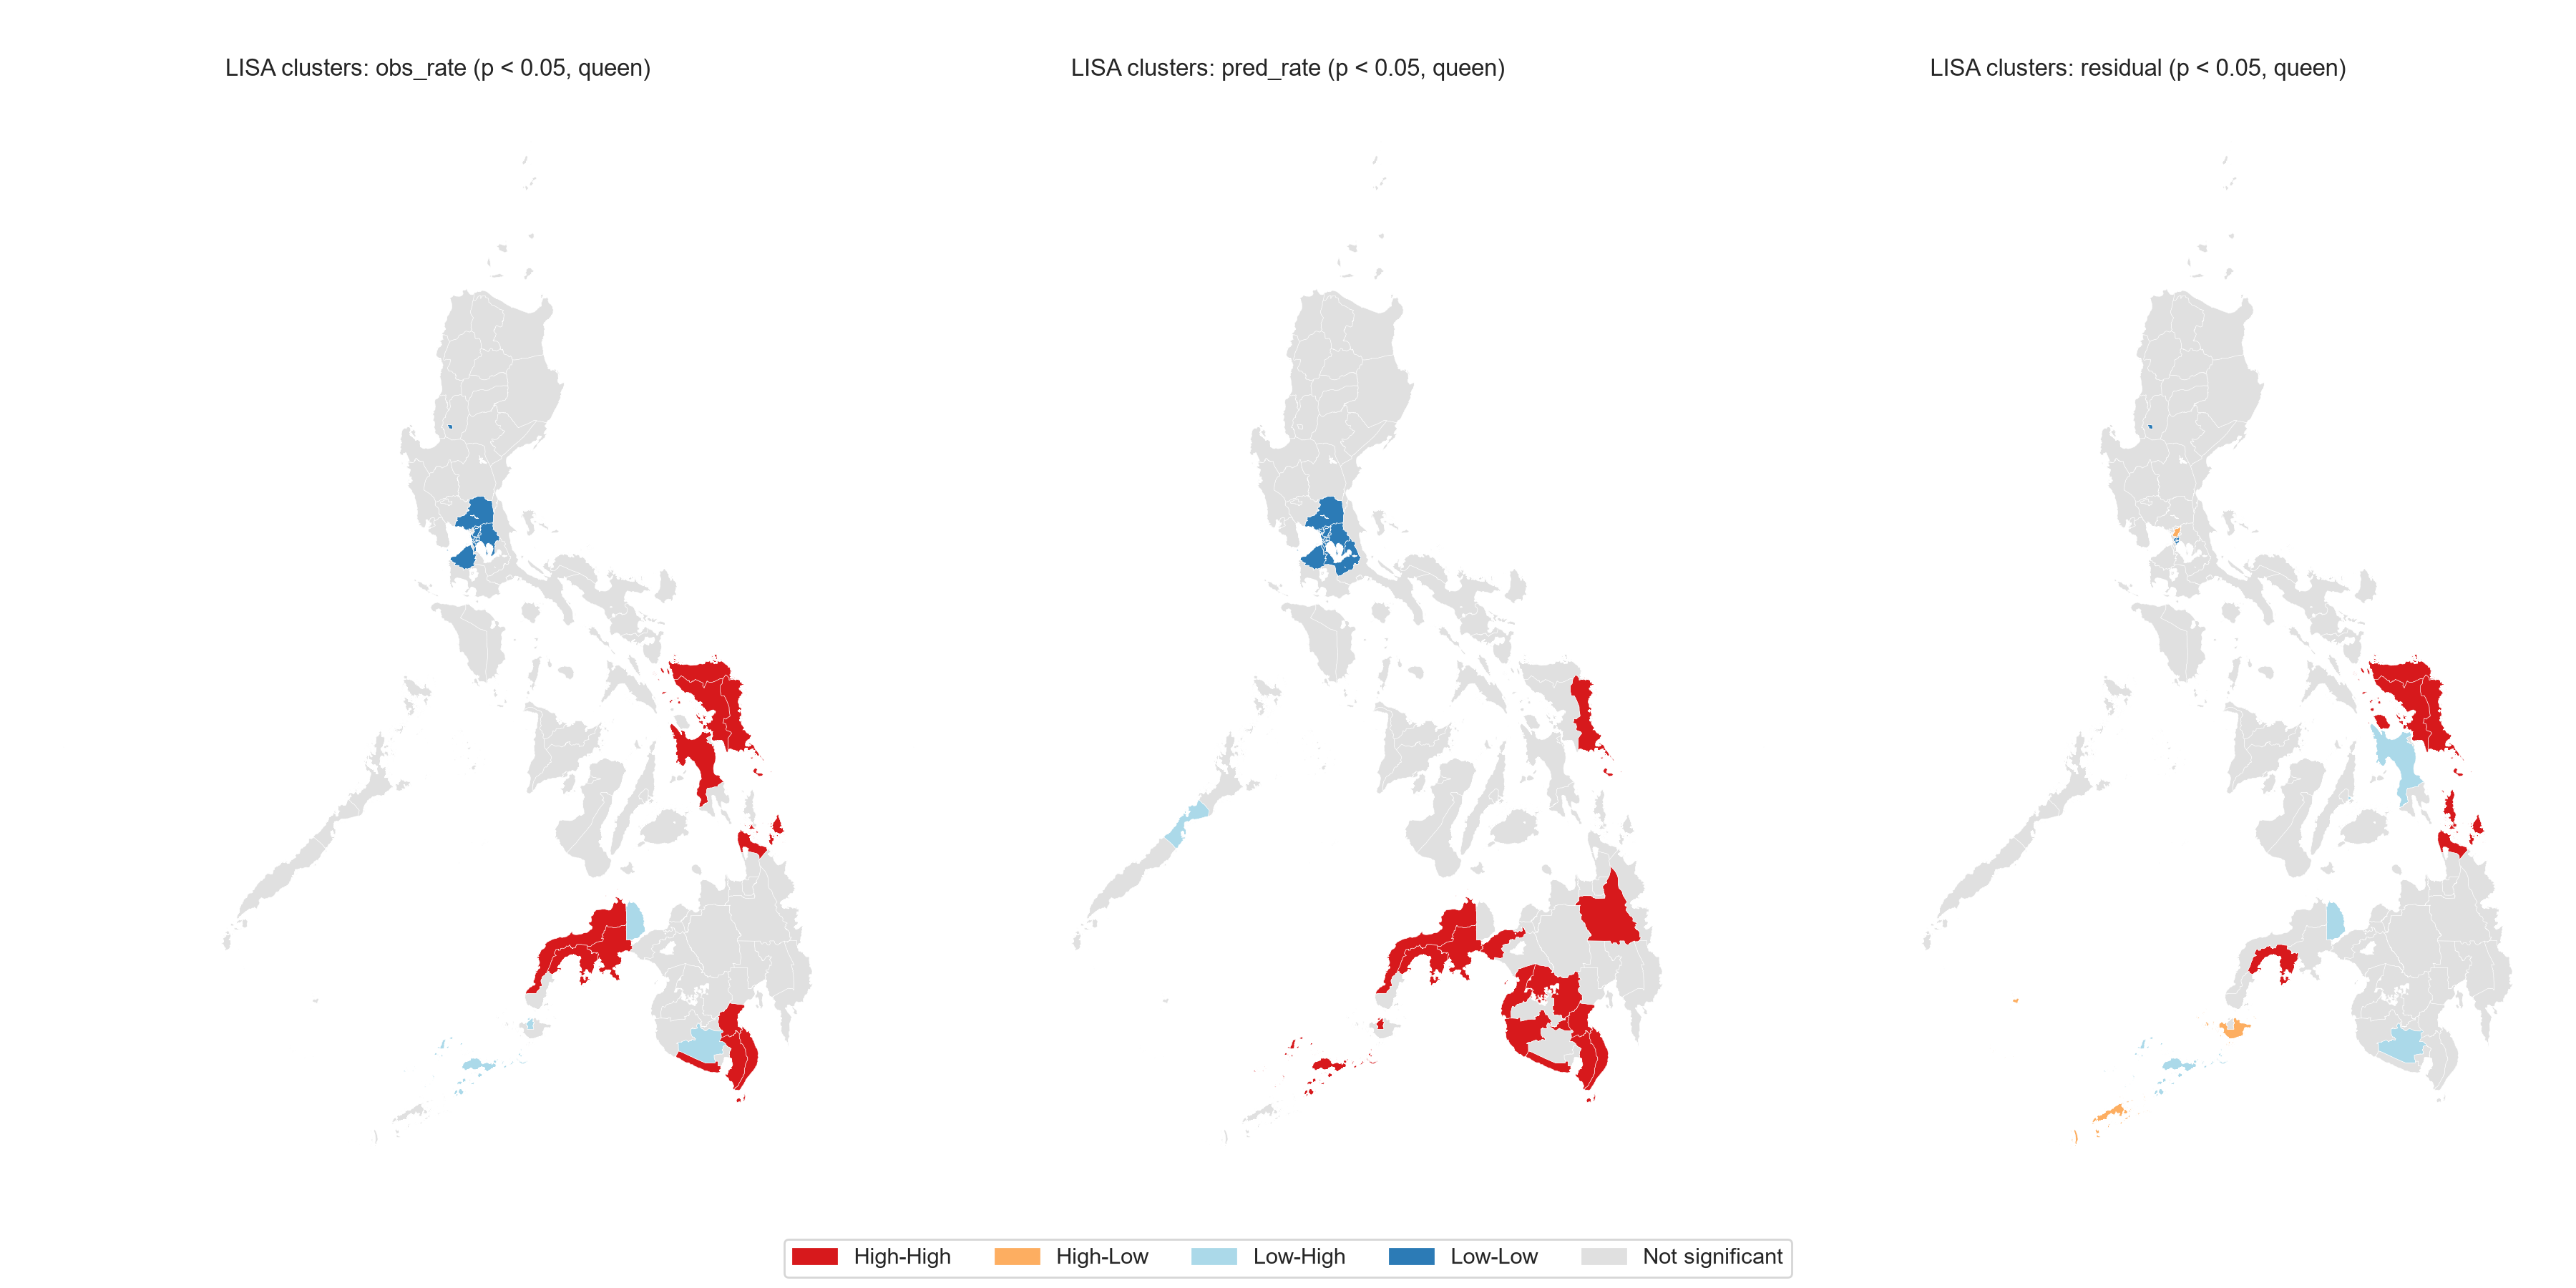

In [8]:
Image(spatial / 'lisa_figures' / 'lisa_cluster_maps.png')

In [9]:
print('High-High (p < 0.05):')
print(', '.join(obs[obs.cluster_p05 == 'High-High'].NAME))

High-High (p < 0.05):
Davao del Sur, Eastern Samar, Leyte, Northern Samar, Samar (Western), Surigao del Norte, Zamboanga del Norte, Zamboanga del Sur, Saranggani, Zamboanga Sibugay, Davao Occidental


Eleven provinces are High-High at p < 0.05: the Samar island group and Leyte, the Zamboanga peninsula, southern Davao, Sarangani and Surigao del Norte. **None survives BH-FDR**, so we call them suggestive. The Metro Manila low-risk cluster is much firmer (8 provinces still significant after correction).

## 4. What would more digital uptake change?

In the 11 hotspot provinces we switch people at random until 10 more percentage points have the internet, or the digital skills, or both, then re-score everyone with their own out-of-fold model. This shows how the model responds. It is not the effect of a policy.

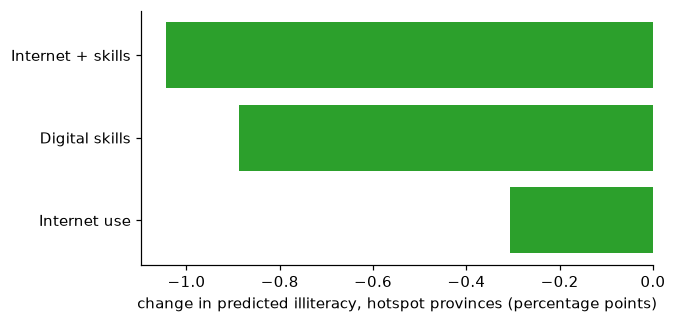

,label,effect_target_pop_pp,effect_national_pp
0,Internet use,-0.31,-0.02
1,Digital skills,-0.89,-0.07
2,Internet + skills,-1.04,-0.08


In [10]:
sim = pd.read_csv(spatial / 'simulation_summary.csv')
labels = {'internet': 'Internet use', 'digital_skills': 'Digital skills', 'digital_package': 'Internet + skills'}
sim['label'] = sim.scenario.map(labels)

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(sim.label, sim.effect_target_pop_pp, color='tab:green')
ax.set_xlabel('change in predicted illiteracy, hotspot provinces (percentage points)')
plt.show()
sim[['label', 'effect_target_pop_pp', 'effect_national_pp']].round(2)

The effects are small: about one percentage point at most in the hotspots, and under 0.1 nationally. Skills move the prediction about three times as much as internet access alone. The hotspot set rests on unadjusted p-values, so it is a working definition of high-risk areas.